# IT24100008 — Model Evaluation and Quality-Control Decision Support

## Step 1: Load the Test Dataset and Trained Models

This section independently evaluates the classification models
developed by Person 3.

The reserved test dataset contains 762 rice observations that
were not used for model training, feature selection, or tuning.

Two trained classification pipelines are loaded:
1. Logistic Regression
2. Tuned Support Vector Machine (SVM)

The evaluation will help determine which model is more suitable
for rice variety classification and quality-control decision support.

In [1]:
# Step 1: Load Test Data and Trained Models

import pandas as pd
import joblib

# Load untouched test dataset
test_df = pd.read_csv("rice_test.csv")

# Load trained models
lr_model = joblib.load(
    "person3_handover/rice_logistic_regression.pkl"
)

svm_model = joblib.load(
    "person3_handover/rice_svm_model.pkl"
)

# Load selected features
selected_features = joblib.load(
    "person3_handover/selected_features.pkl"
)

# Separate inputs and actual labels
X_test = test_df[selected_features]
y_test = test_df["Class"]

print("Test dataset shape:", test_df.shape)
print("Selected features:", selected_features)
print("Test observations:", len(X_test))
print("Class distribution:")
print(y_test.value_counts())

print("\nModels loaded successfully!")

Test dataset shape: (762, 8)
Selected features: ['Perimeter', 'Major_Axis_Length']
Test observations: 762
Class distribution:
Class
Osmancik    436
Cammeo      326
Name: count, dtype: int64

Models loaded successfully!


In [2]:
# Evaluate Logistic Regression and SVM on Test Data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store trained models
models = {
    "Logistic Regression": lr_model,
    "Tuned SVM": svm_model
}

evaluation_results = []

for name, model in models.items():

    # Predict rice variety
    y_pred = model.predict(X_test)

    # Calculate ROC-AUC using decision scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Calculate evaluation metrics
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Osmancik").astype(int),
            y_score
        )
    })

# Create comparison table
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9121,0.9123,0.9077,0.9097,0.9739
1,Tuned SVM,0.9121,0.9123,0.9077,0.9097,0.9530


## Independent Test Set Evaluation

The trained Logistic Regression and tuned SVM models
were evaluated using the reserved test dataset.

The test dataset contains 762 rice observations that
were not used during training or hyperparameter tuning.

Five evaluation metrics were calculated:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-Score
- ROC-AUC

Macro-averaged metrics were selected to give equal
importance to Cammeo and Osmancik despite the
difference in class frequencies.

This evaluation provides evidence of how well the
models generalize to previously unseen rice observations.

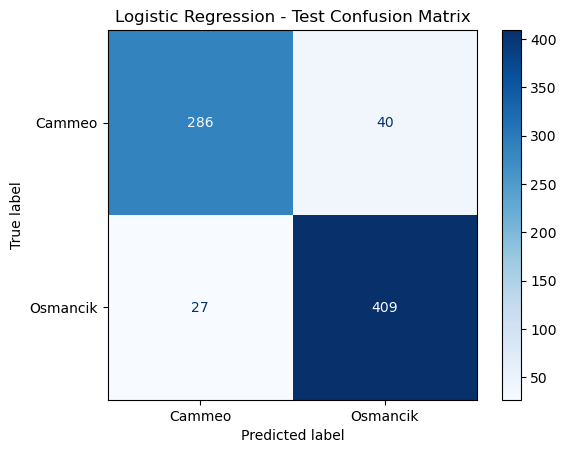


Logistic Regression
Correct predictions: 695
Incorrect predictions: 67
----------------------------------------


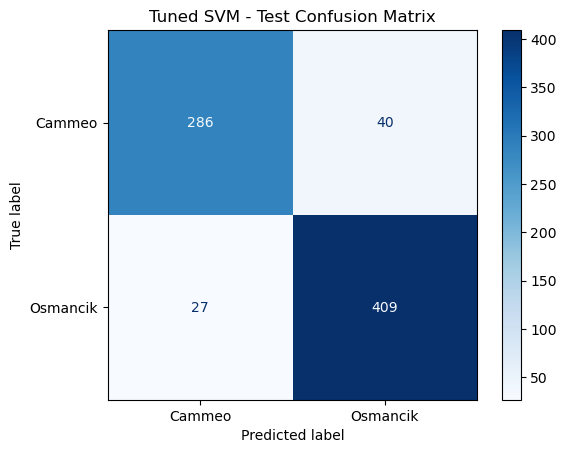


Tuned SVM
Correct predictions: 695
Incorrect predictions: 67
----------------------------------------


In [4]:
# Confusion Matrix Analysis

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

class_labels = ["Cammeo", "Osmancik"]

for name, model in models.items():

    # Predict rice varieties
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    # Display confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    disp.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{name} - Test Confusion Matrix")
    plt.show()

    print(f"\n{name}")
    print("Correct predictions:", cm.trace())
    print("Incorrect predictions:", cm.sum() - cm.trace())
    print("-" * 40)

### Confusion Matrix Interpretation

Both Logistic Regression and tuned SVM achieved
695 correct classifications out of 762 test observations,
resulting in 91.21% accuracy.

Both models produced the same confusion matrix:

| Actual Class | Predicted Cammeo | Predicted Osmancik |
|---|---:|---:|
| Cammeo | 286 | 40 |
| Osmancik | 27 | 409 |

A total of 67 observations were incorrectly classified.

The recall for Cammeo was 87.73%, while the recall
for Osmancik was 93.81%.

These results indicate that Cammeo grains were more
frequently misclassified than Osmancik grains.

For quality-control decision support, these errors
demonstrate the risk of using predicted variety labels
as definitive verification.

The proposed system should support human verification
rather than automatically certify rice authenticity
or overall product quality.

In [5]:
# Step 4: Compare Logistic Regression and SVM Predictions

lr_predictions = lr_model.predict(X_test)
svm_predictions = svm_model.predict(X_test)

# Compare predictions
same_predictions = (lr_predictions == svm_predictions).sum()
different_predictions = (lr_predictions != svm_predictions).sum()

# Compare incorrect predictions
lr_errors = (lr_predictions != y_test.to_numpy())
svm_errors = (svm_predictions != y_test.to_numpy())

both_wrong = (lr_errors & svm_errors).sum()
only_lr_wrong = (lr_errors & ~svm_errors).sum()
only_svm_wrong = (~lr_errors & svm_errors).sum()

print("Prediction Agreement Analysis")
print("-----------------------------")
print("Same predictions:", same_predictions)
print("Different predictions:", different_predictions)
print("Both models incorrect:", both_wrong)
print("Only Logistic Regression incorrect:", only_lr_wrong)
print("Only SVM incorrect:", only_svm_wrong)

Prediction Agreement Analysis
-----------------------------
Same predictions: 758
Different predictions: 4
Both models incorrect: 65
Only Logistic Regression incorrect: 2
Only SVM incorrect: 2


### Model Prediction Agreement Analysis

The predictions of Logistic Regression and tuned SVM
were compared across 762 independent test observations.

Both models produced identical predictions for 758
observations, representing 99.48% agreement.

Only four observations received different predictions.

Both models incorrectly classified the same 65 observations.
Logistic Regression made two additional errors that SVM
avoided, while SVM made two additional errors that
Logistic Regression avoided.

These findings suggest that the two classifiers exhibit
highly similar classification behavior when using
Perimeter and Major_Axis_Length.

The high overlap in errors indicates that simply
combining these two models may offer limited improvement.

Logistic Regression remains the preferred candidate
because of its interpretability and higher test ROC-AUC.

The models should support human variety verification,
not automatically certify rice quality or authenticity.

,Feature,Coefficient,Absolute Coefficient
1,Major_Axis_Length,-3.7540,3.7540
0,Perimeter,-0.9302,0.9302


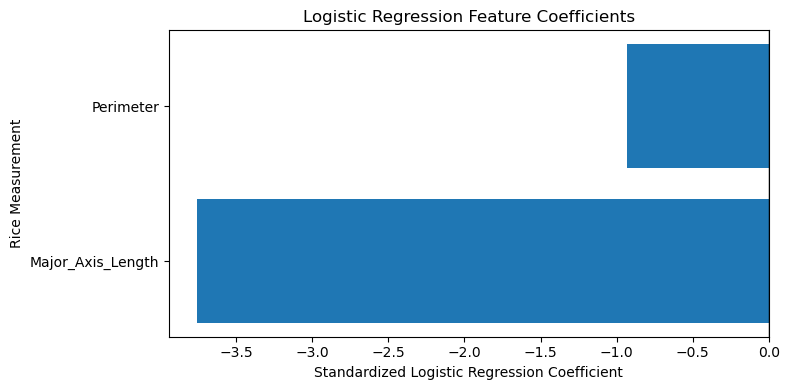

Model classes: ['Cammeo' 'Osmancik']


In [6]:
# Step 5: Logistic Regression Model Explainability

import pandas as pd
import matplotlib.pyplot as plt

# Extract the trained Logistic Regression classifier
lr_classifier = lr_model.named_steps["model"]

# Extract coefficients
coefficients = lr_classifier.coef_[0]

# Create feature coefficient table
coefficient_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficient_df.round(4))

# Plot coefficients
plt.figure(figsize=(8, 4))

plt.barh(
    coefficient_df["Feature"],
    coefficient_df["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Standardized Logistic Regression Coefficient")
plt.ylabel("Rice Measurement")
plt.title("Logistic Regression Feature Coefficients")

plt.tight_layout()
plt.show()

print("Model classes:", lr_classifier.classes_)

### Logistic Regression Explainability

The standardized coefficients of the trained Logistic
Regression model were examined to understand how rice
measurements influence classification decisions.

| Feature | Coefficient |
|---|---:|
| Major_Axis_Length | -3.7540 |
| Perimeter | -0.9302 |

Both coefficients were negative. Since Osmancik is the
positive class, increasing either measurement decreases
the predicted log-odds of Osmancik when the other
measurement is held constant.

Major_Axis_Length had the larger absolute standardized
coefficient, indicating a stronger conditional association
with the model's predictions.

However, the two measurements are correlated, so
coefficient magnitudes should not be interpreted as
independent causal effects.

These findings improve model transparency and help
explain how morphological measurements contribute
to rice variety classification.

In [7]:
# Step 6: Investigate Misclassified Rice Grains

# Get Logistic Regression predictions
lr_predictions = lr_model.predict(X_test)

# Create an analysis DataFrame
error_analysis_df = X_test.copy()

error_analysis_df["Actual_Class"] = y_test.to_numpy()
error_analysis_df["Predicted_Class"] = lr_predictions

# Identify correct and incorrect classifications
error_analysis_df["Correct"] = (
    error_analysis_df["Actual_Class"]
    == error_analysis_df["Predicted_Class"]
)

# Extract misclassified observations
misclassified_df = error_analysis_df[
    ~error_analysis_df["Correct"]
].copy()

print("Total test observations:", len(error_analysis_df))
print("Misclassified observations:", len(misclassified_df))

print("\nMisclassification types:")
print(
    pd.crosstab(
        misclassified_df["Actual_Class"],
        misclassified_df["Predicted_Class"]
    )
)

print("\nSample misclassified observations:")
display(misclassified_df.head(10))

Total test observations: 762
Misclassified observations: 67

Misclassification types:
Predicted_Class  Cammeo  Osmancik
Actual_Class                     
Cammeo                0        40
Osmancik             27         0

Sample misclassified observations:


,Perimeter,Major_Axis_Length,Actual_Class,Predicted_Class,Correct
1,467.765991,193.680939,Osmancik,Cammeo,False
26,458.359009,195.082306,Osmancik,Cammeo,False
38,473.609985,206.225510,Osmancik,Cammeo,False
54,467.023987,191.151123,Osmancik,Cammeo,False
98,492.065002,198.027405,Osmancik,Cammeo,False
101,454.776001,191.120804,Cammeo,Osmancik,False
106,451.799011,192.738800,Osmancik,Cammeo,False
107,456.441010,185.982010,Cammeo,Osmancik,False
134,441.023010,182.752808,Cammeo,Osmancik,False
146,470.100006,197.197021,Osmancik,Cammeo,False


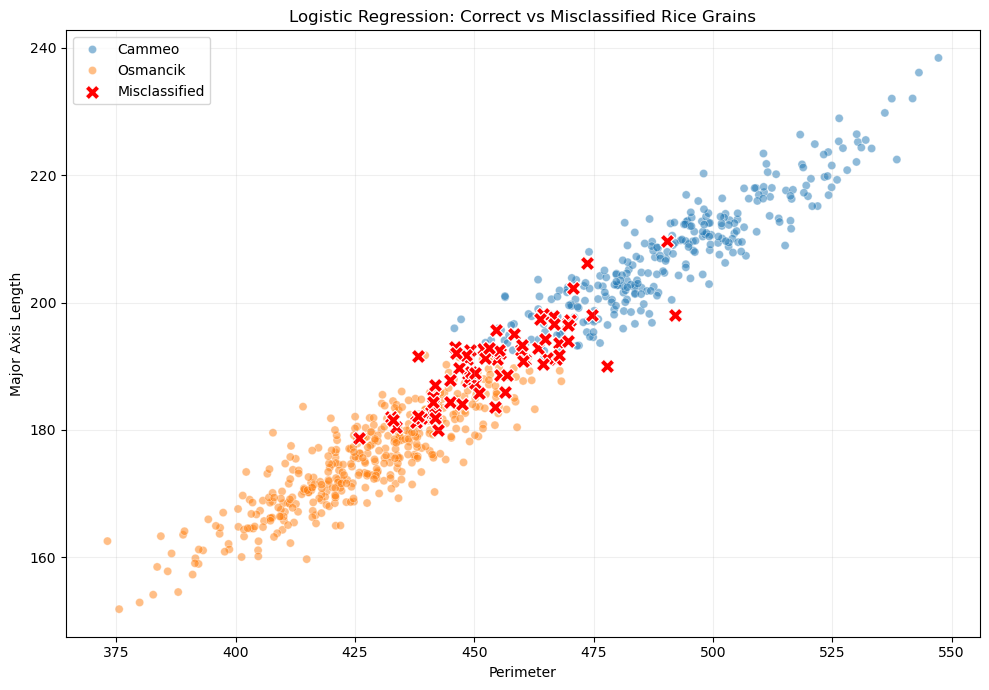

In [8]:
# Step 7: Visualize Correct and Incorrect Predictions

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

# Correctly classified grains
sns.scatterplot(
    data=error_analysis_df[error_analysis_df["Correct"]],
    x="Perimeter",
    y="Major_Axis_Length",
    hue="Actual_Class",
    alpha=0.5,
    s=35
)

# Incorrectly classified grains
sns.scatterplot(
    data=error_analysis_df[~error_analysis_df["Correct"]],
    x="Perimeter",
    y="Major_Axis_Length",
    color="red",
    marker="X",
    s=110,
    label="Misclassified"
)

plt.title("Logistic Regression: Correct vs Misclassified Rice Grains")
plt.xlabel("Perimeter")
plt.ylabel("Major Axis Length")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretation of Classification Error Visualization

The scatter plot shows the relationship between
Perimeter and Major_Axis_Length for the independent
test observations.

Correctly classified Cammeo grains are mainly
concentrated in the upper-right region, while
correctly classified Osmancik grains are mainly
concentrated in the lower-left region.

Most misclassified observations occur in the
overlapping region between the two varieties,
approximately around Perimeter values of 430–475
and Major_Axis_Length values of 180–200.

This suggests that morphological similarity between
some Cammeo and Osmancik grains contributes to
classification difficulty.

The plot also shows a positive relationship between
Perimeter and Major_Axis_Length, consistent with
the earlier correlation analysis.

These findings highlight the limitations of relying
on only two morphological measurements.

For quality-control decision support, uncertain or
potentially misclassified grains should be referred
for additional verification rather than automatically
accepted as correctly identified.

In [9]:
#  Rice Quality-Control Decision Support

def rice_qc_decision(perimeter, major_axis_length, expected_variety):

    # Prepare rice measurements
    sample = pd.DataFrame({
        "Perimeter": [perimeter],
        "Major_Axis_Length": [major_axis_length]
    })

    # Predict variety using trained Logistic Regression
    predicted_variety = lr_model.predict(sample)[0]

    # Compare expected and predicted varieties
    if predicted_variety == expected_variety:
        decision = "MATCH"
        recommendation = (
            "Prediction agrees with expected variety. "
            "Continue standard quality-control procedures."
        )
    else:
        decision = "MISMATCH"
        recommendation = (
            "Prediction differs from expected variety. "
            "Refer the grain for additional verification."
        )

    return {
        "Expected Variety": expected_variety,
        "Predicted Variety": predicted_variety,
        "QC Decision": decision,
        "Recommendation": recommendation
    }


# Test with an example rice grain
result = rice_qc_decision(
    perimeter=450,
    major_axis_length=190,
    expected_variety="Cammeo"
)

for key, value in result.items():
    print(f"{key}: {value}")

Expected Variety: Cammeo
Predicted Variety: Osmancik
QC Decision: MISMATCH
Recommendation: Prediction differs from expected variety. Refer the grain for additional verification.


In [10]:
# Step 8.2: Quality-Control Decision with Model Probabilities

def rice_qc_decision_with_probability(
    perimeter,
    major_axis_length,
    expected_variety
):

    valid_varieties = ["Cammeo", "Osmancik"]

    if expected_variety not in valid_varieties:
        raise ValueError("Expected variety must be Cammeo or Osmancik.")

    sample = pd.DataFrame({
        "Perimeter": [perimeter],
        "Major_Axis_Length": [major_axis_length]
    })

    predicted_variety = lr_model.predict(sample)[0]

    probabilities = lr_model.predict_proba(sample)[0]

    probability_dict = dict(
        zip(lr_model.classes_, probabilities)
    )

    predicted_probability = probability_dict[predicted_variety]

    if predicted_variety == expected_variety:
        decision = "MATCH"
        recommendation = (
            "Prediction agrees with expected variety. "
            "Continue standard quality-control procedures."
        )
    else:
        decision = "MISMATCH"
        recommendation = (
            "Prediction differs from expected variety. "
            "Refer the grain for additional verification."
        )

    return {
        "Expected Variety": expected_variety,
        "Predicted Variety": predicted_variety,
        "Cammeo Probability": round(probability_dict["Cammeo"], 4),
        "Osmancik Probability": round(probability_dict["Osmancik"], 4),
        "Predicted Class Probability": round(predicted_probability, 4),
        "QC Decision": decision,
        "Recommendation": recommendation
    }


# Test the improved system
result = rice_qc_decision_with_probability(
    perimeter=450,
    major_axis_length=190,
    expected_variety="Cammeo"
)

for key, value in result.items():
    print(f"{key}: {value}")

Expected Variety: Cammeo
Predicted Variety: Osmancik
Cammeo Probability: 0.3519
Osmancik Probability: 0.6481
Predicted Class Probability: 0.6481
QC Decision: MISMATCH
Recommendation: Prediction differs from expected variety. Refer the grain for additional verification.


### Interpretation of Quality-Control Decision Support

The proposed quality-control system was tested using
a rice grain with Perimeter = 450 and
Major_Axis_Length = 190.

The expected variety was Cammeo, while the trained
Logistic Regression model predicted Osmancik.

The estimated class probabilities were:

- Cammeo: 35.19%
- Osmancik: 64.81%

Since the predicted variety differed from the expected
variety, the system returned MISMATCH and recommended
additional verification.

These probabilities represent model estimates rather
than guaranteed correctness. They have not been
independently calibrated.

The system is intended to support variety verification,
not automatically certify rice authenticity or quality.

In [11]:
# Step 8.3: Test MATCH Decision

match_result = rice_qc_decision_with_probability(
    perimeter=450,
    major_axis_length=190,
    expected_variety="Osmancik"
)

for key, value in match_result.items():
    print(f"{key}: {value}")

Expected Variety: Osmancik
Predicted Variety: Osmancik
Cammeo Probability: 0.3519
Osmancik Probability: 0.6481
Predicted Class Probability: 0.6481
QC Decision: MATCH
Recommendation: Prediction agrees with expected variety. Continue standard quality-control procedures.


## Step 9: Proposed Rice Variety Verification Workflow

The proposed system provides decision support for rice
variety verification using a trained Logistic Regression
classification model.

### Workflow

1. A quality-control officer enters the rice grain's
   Perimeter and Major_Axis_Length measurements.

2. The saved machine learning pipeline standardizes
   the measurements using the training-fitted scaler.

3. Logistic Regression predicts either Cammeo or
   Osmancik and produces estimated class probabilities.

4. The predicted variety is compared with the expected
   variety supplied by the quality-control officer.

5. If both varieties agree, the system returns MATCH
   and recommends continuing standard QC procedures.

6. If the varieties differ, the system returns MISMATCH
   and recommends additional verification.

### Business Value

The system provides a consistent, reproducible method
for supporting rice variety verification decisions.

It may help quality-control personnel prioritize
potentially inconsistent samples for manual review.

### Limitations

The model achieved 91.21% accuracy on the held-out
test dataset and incorrectly classified 67 of 762 grains.

MATCH does not guarantee authenticity, and MISMATCH
does not prove mislabeling or contamination.

Predicted probabilities have not been independently
calibrated, and the system has not been validated in
a real industrial quality-control environment.

Therefore, the proposed application should remain
a human-supervised decision-support prototype.

##  Critical Evaluation, Limitations and Recommendations

### Model Performance

Logistic Regression was selected as the preferred model
for rice variety classification.

On the independent test dataset containing 762 grains,
the model achieved:

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 91.21% |
| Macro Precision | 91.23% |
| Macro Recall | 90.77% |
| Macro F1-Score | 90.97% |
| ROC-AUC | 97.39% |

The model correctly classified 695 grains and
incorrectly classified 67 grains.

Although these results demonstrate useful predictive
performance, the model is not error-free.

### 10.2 Model Limitations

**1. Classification errors**

The model incorrectly classified 67 of 762 test
observations, representing an error rate of 8.79%.

Therefore, predicted labels should not be treated
as guaranteed correct classifications.

**2. Differences in class-specific recall**

Cammeo recall was 87.73%, compared with 93.81%
for Osmancik.

This indicates that the model was less successful
at identifying Cammeo grains in the test dataset.

**3. Overlapping morphological measurements**

The error-analysis scatter plot showed that many
misclassified grains were located in regions where
Cammeo and Osmancik measurements overlap.

This limits the ability of the selected features
to distinguish every grain correctly.

**4. Limited feature coverage**

The preferred model uses only Perimeter and
Major_Axis_Length.

Although this reduces measurement requirements,
other morphological characteristics may contain
additional useful information.

**5. Limited real-world validation**

The model was evaluated on a held-out portion of
the provided dataset.

It has not been validated using newly collected
samples from real rice-processing facilities.

Its performance under different imaging conditions,
measurement procedures, or grain populations is unknown.

### 10.3 Responsible AI and Business Risks

The system must not automatically certify rice
authenticity, safety, or overall quality.

A MATCH means that the model prediction agrees
with the expected rice variety. It does not
guarantee that the expected label is correct.

A MISMATCH indicates disagreement and should
trigger further verification rather than
automatic rejection.

The model's estimated probabilities have not
been independently calibrated and should not
be interpreted as guaranteed confidence levels.

### 10.4 Recommendations

1. Use Logistic Regression as the preferred
   classification model because of its strong
   observed performance and interpretability.

2. Use the system to assist quality-control
   officers rather than replace human judgement.

3. Refer MISMATCH cases for additional
   verification before taking business action.

4. Continue normal quality-control procedures
   for MATCH cases without treating them as
   proof of authenticity.

5. Validate the model on new rice samples
   collected under realistic operating conditions
   before industrial deployment.

6. Investigate additional measurements,
   probability calibration, and monitoring
   of class-specific error rates in future work.

### 10.5 Final Business Recommendation

The proposed machine learning system demonstrates
the feasibility of using morphological measurements
to support Cammeo and Osmancik rice variety
classification.

Logistic Regression achieved 91.21% independent
test accuracy using only two numerical features.

The system provides practical decision support
by comparing predicted and expected varieties
and identifying disagreements for further review.

However, because classification errors remain,
the proposed solution should be considered a
human-supervised prototype rather than a
fully automated rice certification system.

In [13]:
# Step 11.1: Record Software Versions

import sys
import platform
import pandas as pd
import numpy as np
import sklearn
import joblib

print("Python Version:", sys.version.split()[0])
print("Operating System:", platform.system())
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Scikit-learn Version:", sklearn.__version__)
print("Joblib Version:", joblib.__version__)

print("\nExperiment Configuration")
print("------------------------")
print("Training observations:", 3048)
print("Test observations:", len(X_test))
print("Train/Test Split:", "80% / 20%")
print("Random State:", 42)
print("Cross-validation:", "5-fold Stratified K-Fold")
print("Selected Features:", selected_features)
print("Preferred Model:", "Logistic Regression")

Python Version: 3.13.9
Operating System: Windows
Pandas Version: 2.3.3
NumPy Version: 2.3.5
Scikit-learn Version: 1.7.2
Joblib Version: 1.5.2

Experiment Configuration
------------------------
Training observations: 3048
Test observations: 762
Train/Test Split: 80% / 20%
Random State: 42
Cross-validation: 5-fold Stratified K-Fold
Selected Features: ['Perimeter', 'Major_Axis_Length']
Preferred Model: Logistic Regression


## Reproducibility and Experiment Documentation

### Experimental Configuration

| Component | Configuration |
|---|---|
| Dataset | Rice Cammeo and Osmancik |
| Total observations | 3,810 |
| Training observations | 3,048 |
| Test observations | 762 |
| Train/test split | 80% / 20% |
| Split strategy | Stratified |
| Random state | 42 |
| Cross-validation | 5-fold Stratified K-Fold |
| Selected features | Perimeter, Major_Axis_Length |
| Preprocessing | StandardScaler within pipelines |
| Preferred model | Logistic Regression |
| Independent test accuracy | 91.21% |

### Reproducibility Measures

The dataset was divided into training and testing
subsets using a fixed random state.

The test dataset was reserved for independent evaluation
and was not used during model training or tuning.

StandardScaler was included within the machine learning
pipelines to prevent scaling-related data leakage.

Model configurations, selected features, evaluation
metrics, and trained pipelines were retained to support
reproducibility.

The Python environment and library versions were
recorded to help reproduce the experiment.

### Methodological Limitation

Feature selection was performed using the full training
dataset before subsequent cross-validation comparisons.

Hyperparameter tuning and some performance comparisons
also reused training folds.

Consequently, the cross-validation results may be
optimistic due to model-selection effects.

Nested cross-validation would provide a more rigorous
estimate of performance during model development.

The reserved test dataset provides a separate evaluation
of the selected models, although further external
validation would be necessary before deployment.